Intermediate Deep Learning - Deep Reinforcement Learning
# Session 2: Deep Q-learning

### Task 0 ⚙️: 

**Instructions:**
1. Import necessary libaries and packages

In [4]:
import torch
torch.set_num_threads(1)
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym

from copy import deepcopy
from collections import deque
import random

## Part1: DQN with experience replay and target network
---

### Task 1.1 📝: Create the DQNetwork class
**Instructions:**
1. Take the code from last session

In [5]:
class DQNetwork(nn.Module):
    def __init__(self, state_size, n_actions, hidden_size=64):
        super(DQNetwork, self).__init__()

        self.fc1 = nn.Linear(state_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, n_actions)

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

### Task 1.2 📝: Create the DQNAgent class

**Instructions:**
Complete only `self.target_q_network = ...` in `__init__`: create an independent copy of the main Q-network with the same initial weights, keep it on `self.device`, and set it to evaluation mode.

The remaining initialization is provided, including the batch size, target-update frequency, step counter, optimizer, loss function, and replay buffer. The experience-storage and sampling methods are provided in Task 1.3. The remaining method placeholders belong to Task 1.4.

<details>
<summary>Toolbox 🛠️</summary>

- `deepcopy(network)` creates an independent copy of a network.
- `.to(device)` moves a network to the selected device.
- `.eval()` sets a network to evaluation mode.

</details>


In [6]:
class DQNAgent:
    def __init__(self, lr=0.0001, gamma=0.99, epsilon=1.0, epsilon_decay=0.99, epsilon_min = 0.01, 
                 state_size=4, n_actions=2, batch_size=64, target_update_freq=250, replay_buffer_size=50000, hidden_size=64):
        """
        DQN agent for CartPole-v1
        """

        # DQN hyperparameters
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.batch_size = batch_size
        self.target_update_freq = target_update_freq

        # Environment parameters
        self.state_size = state_size
        self.n_actions = n_actions

        # Device configuration
        if torch.cuda.is_available():
            self.device = torch.device("cuda")  # GPU
        # elif torch.backends.mps.is_available():
        #     self.device = torch.device("mps")  # Metal Performance Shaders for Mac
        else:
            self.device = torch.device("cpu")
        print(f"Using device: {self.device}")

        # Create Q-network
        self.q_network = DQNetwork(state_size, n_actions, hidden_size=hidden_size).to(self.device)

        # Create target Q-network
        self.target_q_network = deepcopy(self.q_network).to(self.device).eval()

        # Step counter for target network updates
        self.step_count = 0

        # Optimizer
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=self.lr)

        # Loss function
        self.criterion = nn.MSELoss()

        # Replay buffer
        self.replay_buffer = deque(maxlen=replay_buffer_size)

    def choose_action(self, state):
        """Epsilon-greedy action selection"""
        if np.random.random() < self.epsilon:
            return np.random.randint(self.n_actions)  # Random action
        else:

            # Convert state to tensor
            state_tensor = torch.tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)

            # Get Q-values from network
            with torch.no_grad():
                q_values = self.q_network(state_tensor)

            # Select action with highest Q-value
            return torch.argmax(q_values).item()

    def store_experience(self, state, action, reward, next_state, done):
        """Store experience in the replay buffer."""
        self.replay_buffer.append((state, action, reward, next_state, done))

    def sample_experiences(self):
        """Sample a mini-batch of experiences from the replay buffer."""
        batch = random.sample(list(self.replay_buffer), self.batch_size)

        # Unzip the batch into separate arrays
        states, actions, rewards, next_states, dones = zip(*batch)
        return np.array(states), np.array(actions), np.array(rewards), np.array(next_states), np.array(dones)

    def train_step(self):
        """One DQN update from replay buffer using target network."""

        # If not enough experiences, return None
        if len(self.replay_buffer) < self.batch_size:
            return None

        # Sample a batch of experiences
        states, actions, rewards, next_states, dones = self.sample_experiences()

        # Convert to tensors
        state_tensor = torch.tensor(states, dtype=torch.float32, device=self.device) # (batch_size, state_size)
        next_state_tensor = torch.tensor(next_states, dtype=torch.float32, device=self.device)   # (batch_size, state_size)
        action_tensor = torch.tensor(actions, dtype=torch.long, device=self.device)  # (batch_size,)
        reward_tensor = torch.tensor(rewards, dtype=torch.float32, device=self.device)   # (batch_size,)
        done_tensor = torch.tensor(dones, dtype=torch.float32, device=self.device)   # (batch_size,)

        # Get current Q-value for the action taken
        current_q = self.q_network(state_tensor).gather(1, action_tensor.unsqueeze(1))  # (batch_size, 1)
        current_q = current_q.squeeze(-1)  # (batch_size,)

        # Calculate target Q-value
        with torch.no_grad():
            next_q_values = self.target_q_network(next_state_tensor)   # (batch_size, n_actions)
            max_next_q = next_q_values.max(dim=1).values    # (batch_size,)
            target_q = reward_tensor + (1.0 - done_tensor) * self.gamma * max_next_q    # (batch_size,)

        # Compute loss
        loss = self.criterion(current_q, target_q)

        # Optimize the network
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # Increment step counter and update target network if needed
        self.step_count += 1
        if self.step_count % self.target_update_freq == 0:
            self.target_q_network.load_state_dict(self.q_network.state_dict())

        return loss.item()

    def decay_epsilon(self):
        """Decay exploration rate"""
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def save_model(self, filepath):
        """Save the trained model"""
        torch.save({
            'model_state_dict': self.q_network.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            'epsilon': self.epsilon
        }, filepath)
        print(f"Model saved to {filepath}")

    def load_model(self, filepath):
        """Load a trained model"""
        checkpoint = torch.load(filepath, map_location=self.device)
        self.q_network.load_state_dict(checkpoint['model_state_dict'])
        self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        self.epsilon = checkpoint['epsilon']
        self.target_q_network.load_state_dict(self.q_network.state_dict())
        self.target_q_network.eval()
        print(f"Model loaded from {filepath}")


### Task 1.3 📝: Store and sample experiences

The complete `store_experience` and `sample_experiences` methods are provided below; no code needs to be completed. They are also included in the `DQNAgent` class.

Each experience contains `(state, action, reward, next_state, done)`. Here, `done` records `terminated`, not `terminated or truncated` (see Task 1.5). Sampling returns NumPy arrays for a randomly selected mini-batch without replacement. The training method checks that the buffer contains enough experiences before sampling.

```python
def store_experience(self, state, action, reward, next_state, done):
    """Store experience in the replay buffer."""
    self.replay_buffer.append((state, action, reward, next_state, done))

def sample_experiences(self):
    """Sample a mini-batch of experiences from the replay buffer."""
    batch = random.sample(list(self.replay_buffer), self.batch_size)

    # Unzip the batch into separate arrays
    states, actions, rewards, next_states, dones = zip(*batch)
    return np.array(states), np.array(actions), np.array(rewards), np.array(next_states), np.array(dones)
```


### Task 1.4 📝: Adapt train_step method

The parts already covered in TD2 are provided: tensor conversion, current Q-value selection, the target formula, loss calculation, backpropagation, and the optimizer update.

**Instructions:**
The check that returns `None` when the replay buffer contains fewer than `self.batch_size` experiences is provided. Complete only these new DQN components:
1. Sample a mini-batch using the method provided in Task 1.3.
2. Obtain the next-state Q-values from the target network.
3. Increment `self.step_count` after each optimizer update and copy the main network weights to the target network every `self.target_update_freq` updates.

**Batch shapes:** States already have shape `(batch_size, state_size)`, so they need no additional batch dimension. `action_tensor.unsqueeze(1)` creates indices of shape `(batch_size, 1)` for `gather`; squeezing the selected values gives `current_q` shape `(batch_size,)`, matching `target_q`.

<details>
<summary>Toolbox 🛠️</summary>

- `destination.load_state_dict(source.state_dict())` copies network weights.
- `%` can be used to check whether the update interval has been reached.

</details>

```python
def train_step(self):
    """One DQN update from replay buffer using target network."""

    # If not enough experiences, return None
    if len(self.replay_buffer) < self.batch_size:
        return None

    # Sample a batch of experiences
    states, actions, rewards, next_states, dones = self.sample_experiences()

    # Convert to tensors
    state_tensor = torch.tensor(states, dtype=torch.float32, device=self.device) # (batch_size, state_size)
    next_state_tensor = torch.tensor(next_states, dtype=torch.float32, device=self.device)   # (batch_size, state_size)
    action_tensor = torch.tensor(actions, dtype=torch.long, device=self.device)  # (batch_size,)
    reward_tensor = torch.tensor(rewards, dtype=torch.float32, device=self.device)   # (batch_size,)
    done_tensor = torch.tensor(dones, dtype=torch.float32, device=self.device)   # (batch_size,)

    # Get current Q-value for the action taken
    current_q = self.q_network(state_tensor).gather(1, action_tensor.unsqueeze(1))  # (batch_size, 1)
    current_q = current_q.squeeze(-1)  # (batch_size,)

    # Calculate target Q-value
    with torch.no_grad():
        next_q_values = self.target_q_network(next_state_tensor)   # (batch_size, n_actions)
        max_next_q = next_q_values.max(dim=1).values    # (batch_size,)
        target_q = reward_tensor + (1.0 - done_tensor) * self.gamma * max_next_q    # (batch_size,)

    # Compute loss
    loss = self.criterion(current_q, target_q)

    # Optimize the network
    self.optimizer.zero_grad()
    loss.backward()
    self.optimizer.step()

    # Increment step counter and update target network if needed
    self.step_count += 1
    if self.step_count % self.target_update_freq == 0:
        self.target_q_network.load_state_dict(self.q_network.state_dict())

    return loss.item()
```


### Task 1.5 📝: Update training function

**Instructions:**
1. Complete the blank under `Store experience in replay buffer`.
2. Adapt the training loop to the agent implemented in the previous tasks.


In [7]:
def train_agent(AgentClass, episodes=1000, render=False, *args, **kwargs):
    """Train a DQN agent with experience replay"""

    # Create environment
    env = gym.make('CartPole-v1', render_mode='human' if render else None)

    # Get state and action dimensions
    state_size = env.observation_space.shape[0]
    n_actions = env.action_space.n

    print(f"State size: {state_size}, Number of actions: {n_actions}")

    # Create an instance of agent
    agent = AgentClass(
        *args,
        state_size=state_size,
        n_actions=n_actions,
        **kwargs
    )

    # Initialize empty lists for rewards and losses
    rewards_per_episode = []
    losses_per_episode = []

    print("Starting training...")
    print("=" * 60)

    for episode in range(episodes):

        # Reset environment
        state, _ = env.reset(seed=episode)
        env.action_space.seed(episode)

        total_reward = 0
        episode_losses = []
        terminated = False
        truncated = False

        while not (terminated or truncated):
            # Choose action
            action = agent.choose_action(state)

            # Take action in environment
            next_state, reward, terminated, truncated, _ = env.step(action)

            # Store experience in replay buffer
            agent.store_experience(state, action, reward, next_state, terminated)

            # Train the agent
            loss = agent.train_step()
            if loss is not None:
                episode_losses.append(loss)

            # Move to next state
            state = next_state
            total_reward += reward

        # Decay exploration rate
        agent.decay_epsilon()

        # Store rewards and losses
        rewards_per_episode.append(total_reward)
        avg_loss = np.mean(episode_losses) if episode_losses else 0.0
        losses_per_episode.append(avg_loss)

        # Print progress every 100 episodes
        if (episode + 1) % 100 == 0:
            avg_reward = np.mean(rewards_per_episode[-100:])
            print(f"Episode {episode + 1}/{episodes}, "
                  f"Avg Reward (last 100): {avg_reward:.2f}, "
                  f"Avg Loss: {avg_loss:.4f},"
                  f"Epsilon: {agent.epsilon:.3f}")

    env.close()
    print("=" * 60)
    print("Training complete!")
    return agent, rewards_per_episode, losses_per_episode


## Part2: Testing and Visualization
---

### Task 2.1 📝: Test function

**Instructions:**
1. Copy `test_agent` and `plot_training_results` functions from last session

In [8]:
def test_agent(agent, episodes=5, render=False):
    """Test the trained agent"""
    env = gym.make('CartPole-v1', render_mode='human' if render else None)

    print("\nTesting trained agent...")
    test_rewards = []

    for episode in range(episodes):
        state, _ = env.reset(seed=10000 + episode)
        env.action_space.seed(episode)

        total_reward = 0
        done = False

        while not done:
            # Choose best action (no exploration)
            state_tensor = torch.tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
            with torch.no_grad():
                q_values = agent.q_network(state_tensor)
            action = torch.argmax(q_values).item()

            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total_reward += reward

        test_rewards.append(total_reward)

        print(f"Test Episode {episode + 1}: Reward = {total_reward}")

    env.close()

    print(f"Average Test Reward: {np.mean(test_rewards):.2f}")
    return test_rewards


In [9]:
def plot_training_results(rewards, losses):
    """
    Plot training results with raw rewards and moving average

    Args:
        rewards (list): List of rewards per episode
    """
    # Create figure with two subplots side by side
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Plot raw rewards in first subplot
    axes[0, 0].plot(rewards, alpha=0.3)
    axes[0, 0].set_title('Raw Rewards per Episode')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Total Reward')
    axes[0, 0].grid(True)

    # Calculate and plot moving average in second subplot
    window_size = min(100, len(rewards))
    moving_avg_reward = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')
    axes[0, 1].plot(moving_avg_reward)
    axes[0, 1].set_title(f'Moving Average Reward (window={window_size})')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Average Reward')
    axes[0, 1].grid(True)

    # Plot raw losses in third subplot
    axes[1, 0].plot(losses, alpha=0.3)
    axes[1, 0].set_title('Raw losses per Episode')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Total Loss')
    axes[1, 0].grid(True)

    # Plot moving average of losses in fourth subplot
    window_size = min(100, len(rewards))
    moving_avg_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
    axes[1, 1].plot(moving_avg_losses)
    axes[1, 1].set_title(f'Moving Average Loss (window={window_size})')
    axes[1, 1].set_xlabel('Episode')
    axes[1, 1].set_ylabel('Average Loss')
    axes[1, 1].grid(True)

    # Adjust layout and display
    plt.tight_layout()
    plt.show()


### Task 2.2 🚀: Train and Evaluate the Agent

**Instructions:**
1. Run the following code blocks to train and evaluate your DQN agent. Compare the results with those obtained using the basic DQN implementation from the previous session.

The training examples use hidden layers of width 128 for DQN and 64 for Double DQN. Both use learning rate `0.0001`, discount factor `0.99`, batch size `64`, replay capacity `50000`, and a target-network update every `250` optimizer steps. Epsilon starts at `1.0`, is multiplied by `0.99` after each episode, and has a minimum of `0.01`. These configurations were tuned separately; they are not a controlled comparison of the two update rules alone.


DQNAgent for CartPole-v1
State size: 4, Number of actions: 2
Using device: cpu
Starting training...
Episode 100/1000, Avg Reward (last 100): 45.72, Avg Loss: 1.9920,Epsilon: 0.366
Episode 200/1000, Avg Reward (last 100): 335.81, Avg Loss: 12.2405,Epsilon: 0.134
Episode 300/1000, Avg Reward (last 100): 412.13, Avg Loss: 0.3045,Epsilon: 0.049
Episode 400/1000, Avg Reward (last 100): 434.79, Avg Loss: 0.0169,Epsilon: 0.018
Episode 500/1000, Avg Reward (last 100): 490.94, Avg Loss: 0.0044,Epsilon: 0.010
Episode 600/1000, Avg Reward (last 100): 352.06, Avg Loss: 9.5665,Epsilon: 0.010
Episode 700/1000, Avg Reward (last 100): 70.21, Avg Loss: 7.5533,Epsilon: 0.010
Episode 800/1000, Avg Reward (last 100): 469.74, Avg Loss: 18.0717,Epsilon: 0.010
Episode 900/1000, Avg Reward (last 100): 456.68, Avg Loss: 1.6513,Epsilon: 0.010
Episode 1000/1000, Avg Reward (last 100): 209.77, Avg Loss: 20.7975,Epsilon: 0.010
Training complete!
Model saved to DQNAgent_cartpole_model.pth

Final Statistics:
  Avera

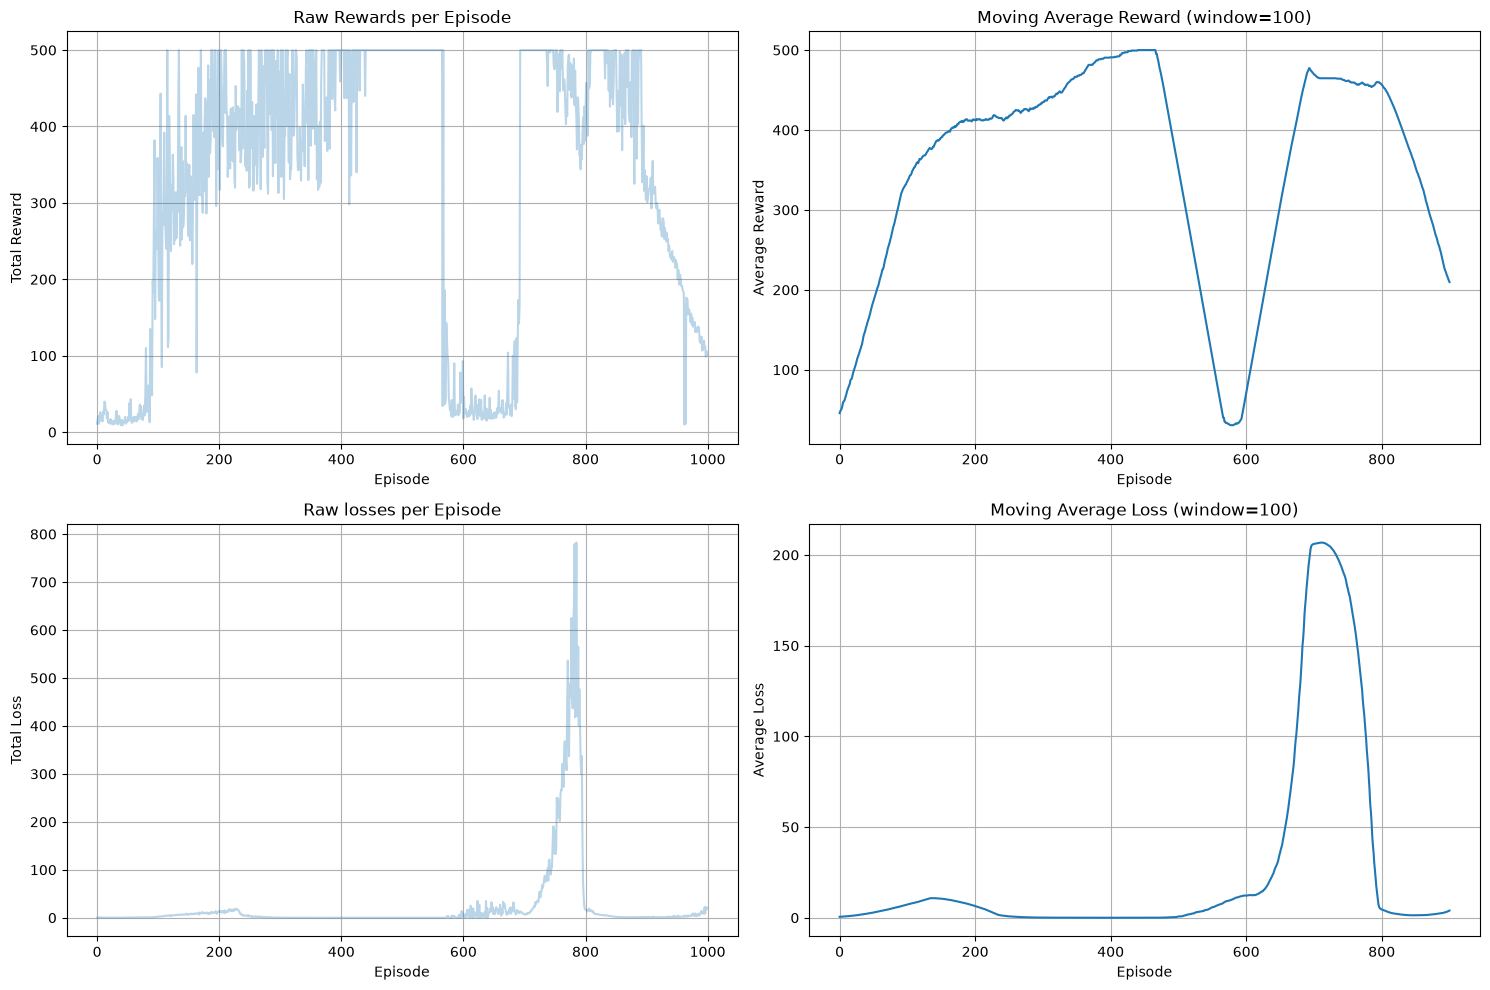


Testing trained agent...
Test Episode 1: Reward = 106.0
Test Episode 2: Reward = 108.0
Test Episode 3: Reward = 109.0
Test Episode 4: Reward = 98.0
Test Episode 5: Reward = 106.0
Average Test Reward: 105.40

Testing trained agent...
Test Episode 1: Reward = 106.0
Test Episode 2: Reward = 108.0
Test Episode 3: Reward = 109.0
Test Episode 4: Reward = 98.0
Test Episode 5: Reward = 106.0
Average Test Reward: 105.40


In [10]:
if __name__ == "__main__":
    # Set random seeds for reproducibility
    seed = 23
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


    agent_class = DQNAgent
    print(f"{agent_class.__name__} for CartPole-v1")
    print("=" * 60)

    # Train the agent
    agent, rewards, losses = train_agent(agent_class, episodes=1000, render=False, hidden_size=128)
    agent.save_model(f"{agent_class.__name__}_cartpole_model.pth")

    # Print final statistics
    print(f"\nFinal Statistics:")
    print(f"  Average reward (last 100 episodes): {np.mean(rewards[-100:]):.2f}")
    print(f"  Best episode reward: {max(rewards):.2f}")
    print(f"  Final epsilon: {agent.epsilon:.3f}")

    # Plot results
    plot_training_results(rewards, losses)

    # Test the trained agent
    # agent.load_model(f"{agent_class.__name__}_cartpole_model.pth")
    test_agent(agent, episodes=5, render=False)

dqn_rewards, dqn_losses, dqn_test_rewards = rewards.copy(), losses.copy(), test_agent(agent, render=False)


## Part3 (Bonus) 🌟: DDQN
---

### Task 3.1 📝: Create the DoubleDQNAgent class
**Instructions:**
1. Create a new class `DoubleDQNAgent` that inherits from `DQNAgent`.


<details>
<summary>Solution 🙈</summary>


```python
class DoubleDQNAgent(DQNAgent):
```

</details>


### Task 3.2 📝: Override train_step method 
**Instructions:**
1. Override the `train_step(self)` method to implement the Double DQN update rule.
    - Use the main Q-network to select the action that maximizes the Q-value for the next state.
    - Use the target Q-network to compute the Q-value of the selected action for the next state.

**Reminder:**
- Per-transition squared error for Double DQN (the implementation averages it over the mini-batch):
    
    $
    \mathcal{L}(\theta) = \left[ r + (1-d) \gamma Q_{\theta^-}(s', \arg\max_{a'} Q_{\theta}(s', a')) - Q_{\theta}(s, a) \right]^2
    $

Here, `d` is the stored `done` flag (`terminated`). Keep the replay sampling, optimizer update, step counter, and target-network synchronization from Task 1.4; only the next-state value calculation changes.

<details>
<summary>Toolbox 🛠️</summary>

- To select the action that maximizes the Q-value for the next state using the main Q-network, you can use the `torch.argmax` function. This function returns the indices of the maximum values along a specified dimension.

```python
next_q_online  = self.q_network(next_state_tensor)   # (batch_size, n_actions)
next_actions = torch.argmax(next_q_online, dim=1, keepdim=True)  # (batch_size, 1)
```
- To compute the Q-value of the selected action for the next state using the target Q-network, you can use the `gather` method.

</details>



In [11]:
class DoubleDQNAgent(DQNAgent):
    def train_step(self):
        """One DQN update from replay buffer using target network."""

        # If not enough experiences, return None
        if len(self.replay_buffer) < self.batch_size:
            return None

        # Sample a batch of experiences
        states, actions, rewards, next_states, dones = self.sample_experiences()

        # Convert to tensors
        state_tensor = torch.tensor(states, dtype=torch.float32, device=self.device) # (batch_size, state_size)
        next_state_tensor = torch.tensor(next_states, dtype=torch.float32, device=self.device)   # (batch_size, state_size)
        action_tensor = torch.tensor(actions, dtype=torch.long, device=self.device)  # (batch_size,)
        reward_tensor = torch.tensor(rewards, dtype=torch.float32, device=self.device)   # (batch_size,)
        done_tensor = torch.tensor(dones, dtype=torch.float32, device=self.device)   # (batch_size,)

        # Get current Q-value for the action taken
        current_q = self.q_network(state_tensor).gather(1, action_tensor.unsqueeze(1))  # (batch_size, 1)
        current_q = current_q.squeeze(-1)  # (batch_size,)

        # Calculate target Q-value
        with torch.no_grad():
            next_actions = self.q_network(next_state_tensor).argmax(dim=1, keepdim=True)
            max_next_q = self.target_q_network(next_state_tensor).gather(1, next_actions).squeeze(1)
            target_q = reward_tensor + (1.0 - done_tensor) * self.gamma * max_next_q    # (batch_size,)

        # Compute loss
        loss = self.criterion(current_q, target_q)

        # Optimize the network
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # Increment step counter and update target network if needed
        self.step_count += 1
        if self.step_count % self.target_update_freq == 0:
            self.target_q_network.load_state_dict(self.q_network.state_dict())

        return loss.item()


### Task 3.3 🚀: Train and Evaluate the Agent

**Instructions:**
1. Run the following code blocks to train and evaluate your DDQN agent. Compare the results with those obtained using the DQN agent.

DoubleDQNAgent for CartPole-v1
State size: 4, Number of actions: 2
Using device: cpu
Starting training...
Episode 100/1000, Avg Reward (last 100): 15.73, Avg Loss: 0.7760,Epsilon: 0.366
Episode 200/1000, Avg Reward (last 100): 39.04, Avg Loss: 1.8052,Epsilon: 0.134
Episode 300/1000, Avg Reward (last 100): 141.90, Avg Loss: 7.2656,Epsilon: 0.049
Episode 400/1000, Avg Reward (last 100): 224.73, Avg Loss: 8.3423,Epsilon: 0.018
Episode 500/1000, Avg Reward (last 100): 292.46, Avg Loss: 1.8453,Epsilon: 0.010
Episode 600/1000, Avg Reward (last 100): 115.32, Avg Loss: 52.1455,Epsilon: 0.010
Episode 700/1000, Avg Reward (last 100): 348.76, Avg Loss: 1.4575,Epsilon: 0.010
Episode 800/1000, Avg Reward (last 100): 457.28, Avg Loss: 0.0326,Epsilon: 0.010
Episode 900/1000, Avg Reward (last 100): 500.00, Avg Loss: 0.0017,Epsilon: 0.010
Episode 1000/1000, Avg Reward (last 100): 498.40, Avg Loss: 0.1908,Epsilon: 0.010
Training complete!
Model saved to DoubleDQNAgent_cartpole_model.pth

Final Statistic

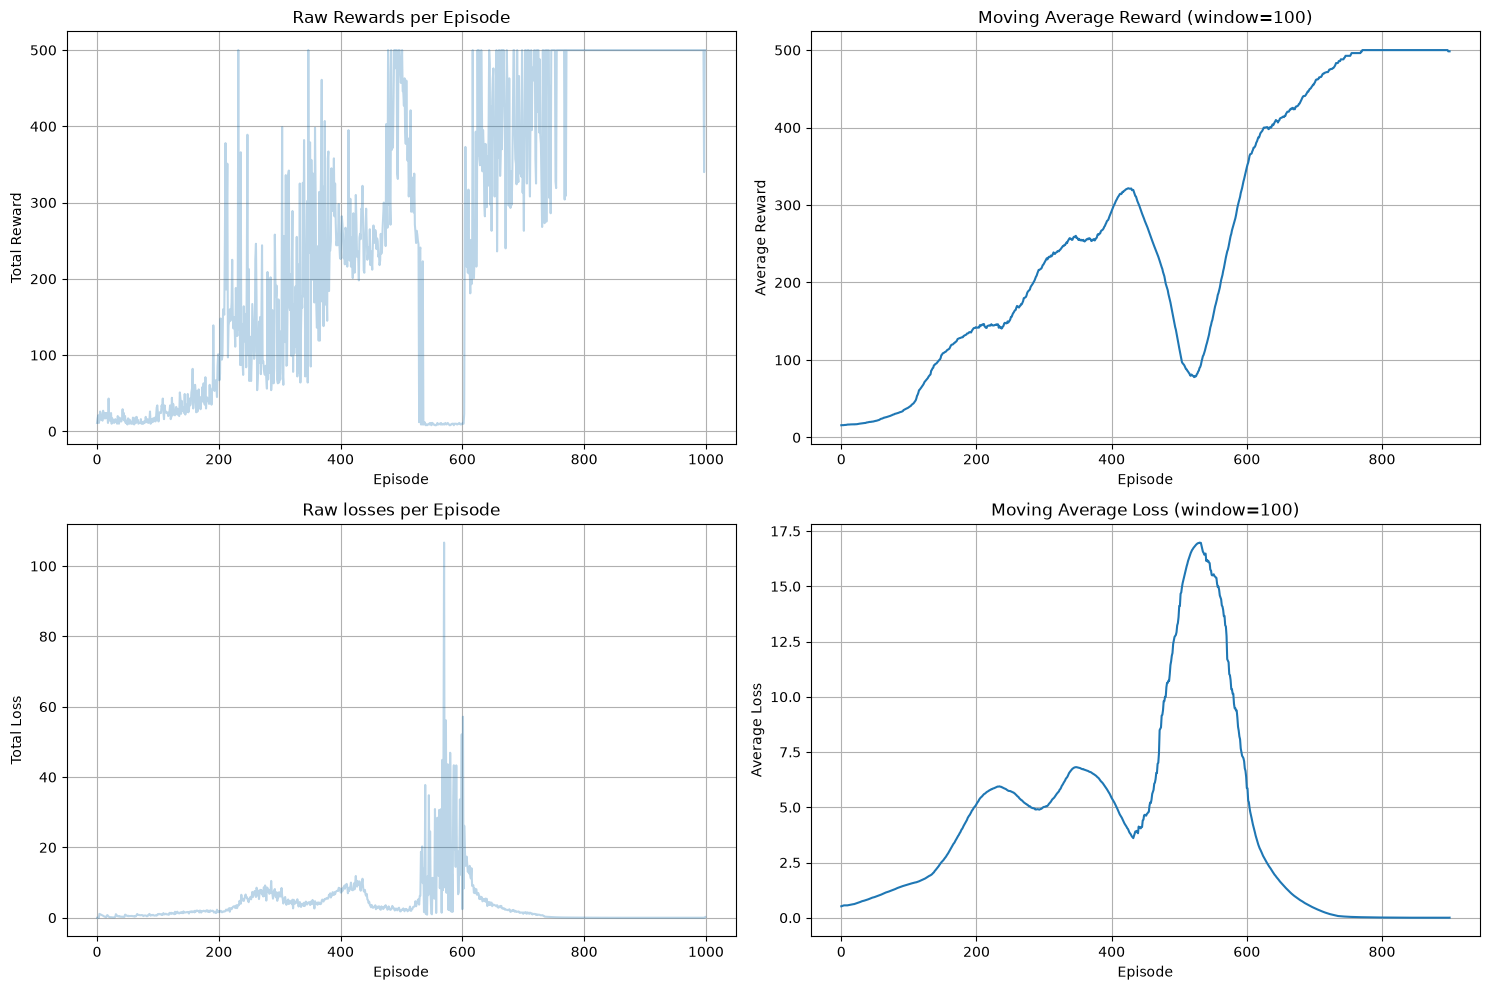


Testing trained agent...
Test Episode 1: Reward = 500.0
Test Episode 2: Reward = 500.0
Test Episode 3: Reward = 500.0
Test Episode 4: Reward = 500.0
Test Episode 5: Reward = 500.0
Average Test Reward: 500.00

Testing trained agent...
Test Episode 1: Reward = 500.0
Test Episode 2: Reward = 500.0
Test Episode 3: Reward = 500.0
Test Episode 4: Reward = 500.0
Test Episode 5: Reward = 500.0
Average Test Reward: 500.00


In [12]:
if __name__ == "__main__":
    # Set random seeds for reproducibility
    seed = 23
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


    agent_class = DoubleDQNAgent
    print(f"{agent_class.__name__} for CartPole-v1")
    print("=" * 60)

    # Train the agent
    agent, rewards, losses = train_agent(agent_class,episodes=1000, render=False, hidden_size=64)
    agent.save_model(f"{agent_class.__name__}_cartpole_model.pth")

    # Print final statistics
    print(f"\nFinal Statistics:")
    print(f"  Average reward (last 100 episodes): {np.mean(rewards[-100:]):.2f}")
    print(f"  Best episode reward: {max(rewards):.2f}")
    print(f"  Final epsilon: {agent.epsilon:.3f}")

    # Plot results
    plot_training_results(rewards, losses)

    # Test the trained agent
    # agent.load_model("dqn_cartpole_model.pth")
    test_agent(agent, episodes=5, render=False)

ddqn_test_rewards = test_agent(agent, render=False)


In [13]:
print(f'DQN greedy mean: {np.mean(dqn_test_rewards):.1f}; Double DQN greedy mean: {np.mean(ddqn_test_rewards):.1f}')


DQN greedy mean: 105.4; Double DQN greedy mean: 500.0


### Interpretation
Replay reduces consecutive-sample correlation and reuses data; a periodically synchronized target makes the regression target less volatile. Double DQN selects next actions with the online network and evaluates them with the target network, reducing maximization bias. It does not guarantee higher returns in every run. Compare training curves and held-out greedy episodes, and repeat across seeds. The provided 128-wide DQN and 64-wide Double DQN differ in capacity, so their scores do not isolate the update rule; use matching widths for a controlled comparison.


### Observed comparison
Both algorithms trained for 1,000 episodes with seed 23. DQN greedy rewards were **[106.0, 108.0, 109.0, 98.0, 106.0]**, mean **105.4**. Double DQN greedy rewards were **[500.0, 500.0, 500.0, 500.0, 500.0]**, mean **500.0**. Compare these with basic DQN's mean **325.8** and tabular Q-learning's mean **132.4** on the same five held-out environment seeds.

The hidden widths differ (128 for DQN and 64 for Double DQN), so this run does not isolate the effect of Double DQN. Five reset seeds from one trained model are insufficient to assess variability across training runs.

For verification, the independent DQN and Double DQN sections ran in separate seeded kernels and their outputs were combined here. This accounts for execution counts restarting in the bonus section. Run All executes the same code sequentially.
